# Research note charts for US PCE dynamics

In [ ]:
# Librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from fismi import utils
import matplotlib.dates as mdates
from fismi.data import query
from matplotlib.ticker import MultipleLocator
import json
import matplotlib.dates as mdates
from fismi import figures

np.set_printoptions(suppress=True, precision=4)
plt.rcParams["figure.figsize"] = (9, 5)

In [24]:
# Setting
startDate = "1995-01-01"

In [25]:
# Import data
## ISMI
dfIsmi = pd.read_excel("output/USIsmiOutput.xlsx")
dfIsmi = dfIsmi[dfIsmi.TIME_PERIOD >= startDate]
dfIsmi = dfIsmi.set_index("TIME_PERIOD")

## Persistance
dfFilterResults = pd.read_excel("output/time-varying-persistance.xlsx")
dfFilterResults = dfFilterResults.set_index("Date")

In [26]:
# We compute headline inflation (PCE variation over a 12-month period)
YoY = dfFilterResults["headlinePce"].to_numpy()*100
MoM = dfFilterResults["monthlyPce"].to_numpy()*100

In [27]:
# Get 5y5y Inflation Expectations
# Query data ; API key
with open('/Users/lea_gosselin/.openbb_platform/user_settings.json', 'r') as file:
    keys = json.load(file)
    
key=keys["credentials"].get("fred_api_key") 

tick = "T5YIFR"
url = f"https://api.stlouisfed.org/fred/series/observations?series_id={tick}&api_key={key}&file_type=json"
# df = sdxData.queryFredData(url)
# df.columns = ["5y5yExpectations"]

In [28]:
# Get FOMC dates
fomcDates = pd.read_excel("fomcDatesHistory.xlsx")
fomcDates = fomcDates.set_index("date",drop=True)
# fomcDatesRes = fomcDates[fomcDates.index > df.index[0]]

In [29]:
# Get FED hawkish regimes
mpRegimes = pd.read_excel("MonetaryRegimes.xlsx").iloc[:, :2]
mpRegimes.columns = ["Date", "MP_Factor_US"]
mpRegimes["Date"] = pd.to_datetime(mpRegimes["Date"])
mpRegimes = mpRegimes.set_index("Date")

### Functions

In [30]:
def addHawkishRegimes(ax, starts, ends, color="pink", alpha=0.05):
    
    for start, end in zip(starts, ends):

        # Shaded regime
        ax.axvspan(
            start,
            end,
            color=color,
            alpha=alpha
        )

        # # Regime boundaries
        # ax.axvline(
        #     start,
        #     color=color,
        #     linewidth=0.8,
        #     alpha=0.7
        # )

        # ax.axvline(
        #     end,
        #     color=color,
        #     linewidth=0.8,
        #     alpha=0.7
        # )

In [31]:
# Add FOMC dates on charts
def addLinesFomc(ax, fomc, col):
    
    # Convert FOMC dates to datetime
    fomc = pd.to_datetime(fomc, errors="coerce").dropna()

    # Get chart date boundaries
    xmin, xmax = ax.get_xlim()
    
    xmin = pd.to_datetime(mdates.num2date(xmin)).tz_localize(None)
    xmax = pd.to_datetime(mdates.num2date(xmax)).tz_localize(None)

    # Keep only FOMC dates within chart
    fomc = fomc[(fomc >= xmin) & (fomc <= xmax)]

    # Add vertical lines
    for date in fomc:
        ax.axvline(
            x=date,
            linestyle="--",
            color=col,
            alpha=0.5,
            linewidth=0.8,
            zorder=0
        )

## Weights per components of the PCE

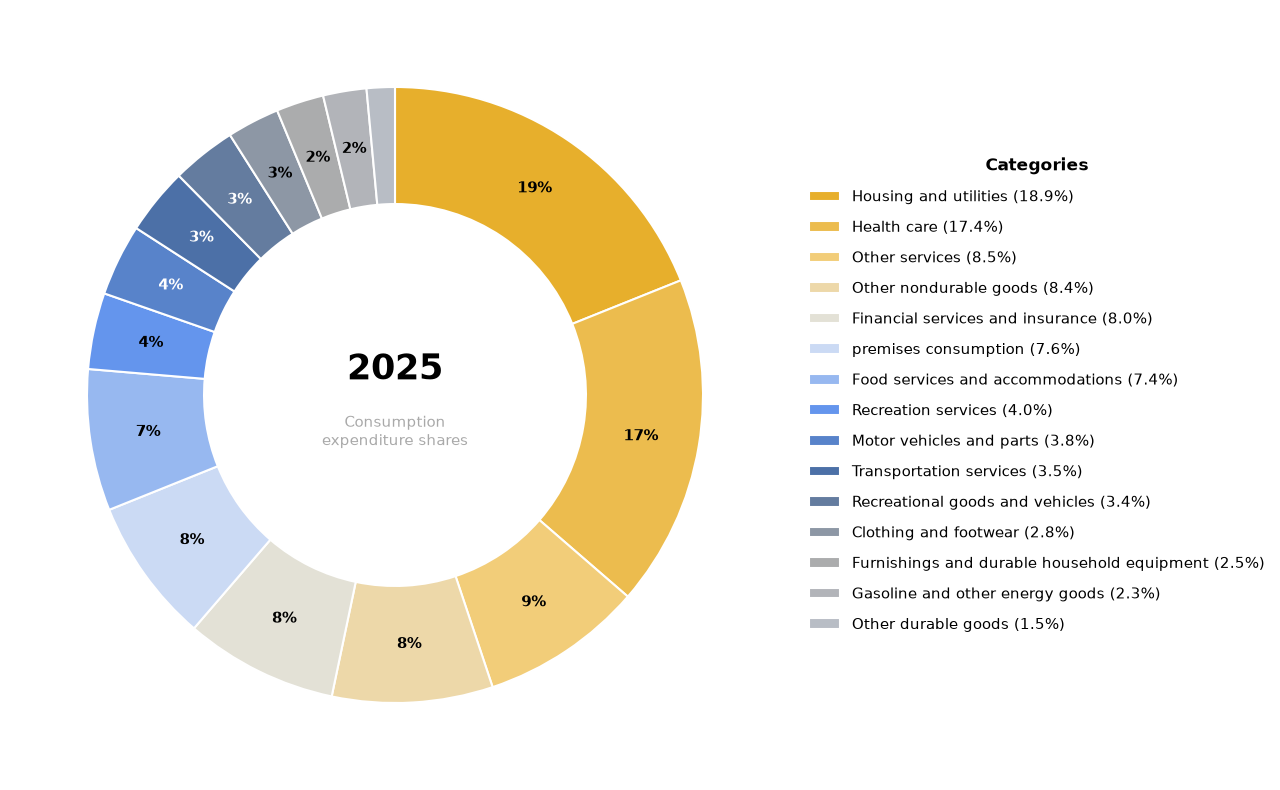

In [32]:
dfW = pd.read_parquet(f"input/USnormedWeightsLvl2.parquet") 
utils.plotConsumptionShares(dfW, yyyy=2025, title="Weighting by Category in the PCE Basket in 2025")

In [33]:
dfW[(dfW.index >= "2025-01-01 00:00:00") &
    (dfW.index < "2026-01-01 00:00:00")].mean()*100

LineDescription
Clothing and footwear                                         2.762846
Financial services and insurance                              8.139392
Food and beverages purchased for off-premises consumption     7.523421
Food services and accommodations                              7.384479
Furnishings and durable household equipment                   2.488709
Gasoline and other energy goods                               2.068159
Health care                                                  17.614983
Housing and utilities                                        18.826475
Motor vehicles and parts                                      3.778983
Other durable goods                                           1.486355
Other nondurable goods                                        8.504066
Other services                                                8.558858
Recreation services                                           3.971803
Recreational goods and vehicles                              

## Flag dovish versus hawkish regimes


In [34]:
# Find beginning / end of Hawhkish cycle
mpRegimes["Month"] = mpRegimes.index.to_period("M").to_timestamp("M")

hawkishMonthly = pd.DataFrame(
    mpRegimes
    .groupby("Month")["MP_Factor_US"]
    .apply(lambda x: (x > 0.6).any())
    .astype(int)
)

# Resize on DF index
hawkishMonthly["StartDate"] = pd.NaT
hawkishMonthly["EndDate"] = pd.NaT

# Beginning of hawkish regime: 0 -> 1
startMask = (
    (hawkishMonthly["MP_Factor_US"] == 1) &
    (hawkishMonthly["MP_Factor_US"].shift(1, fill_value=0) == 0)
)

# End of hawkish regime: 1 -> 0
endMask = (
    (hawkishMonthly["MP_Factor_US"] == 1) &
    (hawkishMonthly["MP_Factor_US"].shift(-1, fill_value=0) == 0)
)

hawkishMonthly.loc[startMask, "StartDate"] = hawkishMonthly.index[startMask]
hawkishMonthly.loc[endMask, "EndDate"] = hawkishMonthly.index[endMask]

# Start / Ends
starts = hawkishMonthly.index[startMask]
ends   = hawkishMonthly.index[endMask]

hawkishPeriods = pd.DataFrame({
    "StartDate": starts,
    "EndDate": ends
})

In [35]:
# # Add to plot the regimes...
# ax1, ax2, ax3, ax4, ax5, ax6, ax7 = axes

# # Fed Hawkish
# for ax in axes:
#     addHawkishRegimes(
#         ax,
#         starts,
#         ends,
#         color="pink",
#         alpha=0.15
#     )

In [36]:
# fig, ax = plt.subplots(figsize=(20, 6))

# # Secondary Y-axis
# ax2 = ax.twinx()

# # ISMI (left axis)
# ax.plot(
#     dfIsmi.index,
#     dfIsmi["ISMIndex"],
#     color="darkslateblue",
#     linewidth=1.5,
#     label="ISM Index",
#     zorder=3
# )

# # Headline inflation (right axis)
# ax2.plot(
#     dfFilterResults.index,
#     dfFilterResults["headlinePce"]*100,
#     color="darkgrey",
#     linewidth=1.5,
#     label="Headline PCE inflation (%)",
#     zorder=2
# )

# # Zero line
# ax.axhline(0, color="black", linewidth=0.8)

# # Labels
# ax.set_ylabel("ISM Index")
# ax2.set_ylabel("Headline inflation (%)", color="black")
# ax2.tick_params(axis="y", labelcolor="black")

# ax.set_title(
#     "Inflation Shock Momentum Index and Headline Inflation",
#     fontweight="bold"
# )

# # Grid
# ax.grid(axis="both", linestyle="--", alpha=0.3)
# ax.set_axisbelow(True)

# # X-axis limits
# ax.set_xlim(
#     pd.Timestamp("1995-01-01"),
#     dfIsmi.index.max()
# )

# # X-axis ticks
# ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
# ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))

# ax.tick_params(axis="x", rotation=90)
# ax.margins(x=0)

# # Common legend
# lines1, labels1 = ax.get_legend_handles_labels()
# lines2, labels2 = ax2.get_legend_handles_labels()

# ax.legend(
#     lines1 + lines2,
#     labels1 + labels2,
#     loc="upper left",
#     ncol=2,
#     frameon=False
# )

# plt.tight_layout()
# plt.show()


# Chart 1

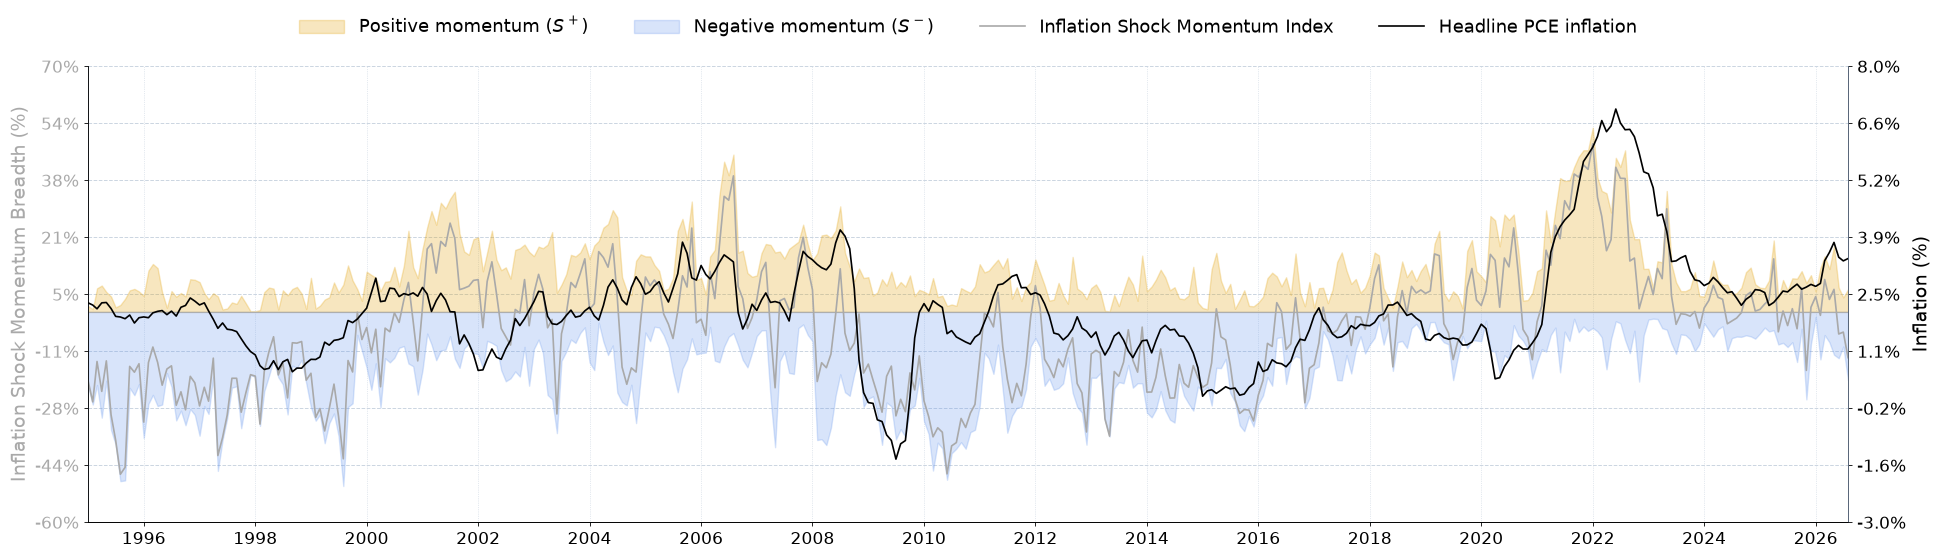

In [37]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator, FuncFormatter

# -------------------------------------------------------
# Colors
# -------------------------------------------------------
COLORS = {
    "positive": "#E39F00D3",
    "negative": "cornflowerblue",
    "ismi":     "darkgrey",
    "headline": "black",
    "grid":     "#CBD5E1",
}

# -------------------------------------------------------
# Data
# -------------------------------------------------------
df = dfIsmi.loc["1995-01-01":].copy().sort_index()

# Adjust column name and units if necessary
headline = dfFilterResults["headlinePce"]*100  

s_plus = df["ISMI+"]*100 #.rolling(12).sum()*100
s_minus = df["ISMI-"]*100 #.rolling(12).sum()*100
ismi = df["ISMIndex"]*100 #.rolling(12).sum()*100

# -------------------------------------------------------
# Figure
# -------------------------------------------------------

fig, ax1 = plt.subplots(figsize=(20, 6))
ax2 = ax1.twinx()

# Positive momentum
ax1.fill_between(
    df.index, 0, s_plus,
    color=COLORS["positive"],
    alpha=0.25,
    label=r"Positive momentum ($S^+$)",
    zorder=2
)

# Negative momentum
ax1.fill_between(
    df.index, 0, -s_minus,
    color=COLORS["negative"],
    alpha=0.25,
    label=r"Negative momentum ($S^-$)",
    zorder=2
)

# ISMI
ax1.plot(
    df.index, ismi,
    color=COLORS["ismi"],
    linewidth=1.2,
    # linestyle='dashed',
    label=r"Inflation Shock Momentum Index",
    zorder=4
)

# Headline inflation (right axis)
ax2.plot(
    df.index, headline,
    color=COLORS["headline"],
    linewidth=1.2,
    linestyle="-",
    label="Headline PCE inflation",
    zorder=5
)


# -------------------------------------------------------
# Axis limits: include ALL observations
# -------------------------------------------------------

# Left axis: S+, -S-, ISMI
left_values = np.concatenate([
    s_plus.to_numpy(dtype=float),
    -s_minus.to_numpy(dtype=float),
    ismi.to_numpy(dtype=float),
    [0.0]
])
left_values = left_values[np.isfinite(left_values)]

# Right axis: headline inflation
# Only retain observations within the displayed date range
headline_visible = headline.loc[
    (headline.index >= df.index.min()) &
    (headline.index <= df.index.max())
]

right_values = headline_visible.to_numpy(dtype=float)
right_values = right_values[np.isfinite(right_values)]

# -------------------------------------------------------
# Nice limits with padding
# -------------------------------------------------------

def nice_limits(values, padding=0.10, step=10):
    vmin = np.min(values)
    vmax = np.max(values)

    span = vmax - vmin
    if span == 0:
        span = max(abs(vmax), 1.0)

    lower = vmin - padding * span
    upper = vmax + padding * span

    lower = np.floor(lower / step) * step
    upper = np.ceil(upper / step) * step

    return lower, upper

# Left axis: rounded to multiples of 10 pp
ymin1, ymax1 = nice_limits(
    left_values,
    padding=0.10,
    step=10
)

# Right axis: rounded to multiples of 1 pp
ymin2, ymax2 = nice_limits(
    right_values,
    padding=0.10,
    step=1
)

ax1.set_ylim(ymin1, ymax1)
ax2.set_ylim(ymin2, ymax2)

# -------------------------------------------------------
# Perfectly aligned horizontal gridlines
# -------------------------------------------------------

# Same number of intervals on both axes
n_intervals = 8

ticks_left = np.linspace(
    ymin1, ymax1, n_intervals + 1
)

ticks_right = np.linspace(
    ymin2, ymax2, n_intervals + 1
)

ax1.set_yticks(ticks_left)
ax2.set_yticks(ticks_right)

# Format tick labels
ax1.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:.0f}%")
)

ax2.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:.1f}%")
)


# -------------------------------------------------------
# Styling
# -------------------------------------------------------
ax1.axhline(
    0, color=COLORS["ismi"],
    linewidth=0.8, alpha=0.8
)

ax1.set_ylabel(
    "Inflation Shock Momentum Breadth (%)",
    color=COLORS["ismi"],
    fontsize=14
)
ax2.set_ylabel(
    "Inflation (%)",
    color=COLORS["headline"],
    fontsize=14
)

ax1.tick_params(axis="y", labelcolor=COLORS["ismi"], labelsize=12)
ax2.tick_params(axis="y", labelcolor=COLORS["headline"], labelsize=12)

# Grid: left axis only
ax1.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    color=COLORS["grid"],
    # alpha=0.65
)
ax1.set_axisbelow(True)
ax2.grid(False)

# Keep headline visible above filled areas
ax1.set_zorder(1)
ax2.set_zorder(2)
ax2.patch.set_visible(False)

# X-axis
ax1.set_xlim(pd.Timestamp("1995-01-01"), df.index.max())

ax1.xaxis.set_major_locator(
    mdates.YearLocator(2)
)

ax1.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

ax1.tick_params(
    axis="x",
    rotation=0,
    labelsize=12
)

# Vertical gridlines
ax1.grid(
    axis="x",
    linestyle=":",
    linewidth=0.5,
    color=COLORS["grid"],
    # alpha=0.35
)

# Spines
for ax in (ax1, ax2):
    ax.spines["top"].set_visible(False)
    ax.spines["bottom"].set_linewidth(0.6)
    ax.spines["left"].set_linewidth(0.6)
    ax.spines["right"].set_linewidth(0.6)

    ax.tick_params(
        axis="both",
        which="major",
        width=0.6,
        length=3
    )
    
# Axis colors
ax1.spines["left"].set_color("#64748B")
ax2.spines["right"].set_color("#64748B")

# Vertical line
# ax2.axhline(2, color="black", linestyle="dashed", linewidth=0.8)

# Combined legend
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

fig.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.99),
    ncol=4,
    frameon=False,
    fontsize=13,
    columnspacing=2.5,
    handlelength=2.5
)

fig.subplots_adjust(
    top=0.88,
    bottom=0.12,
    left=0.06,
    right=0.94
)

plt.show()


In [38]:
dfIsmi["ISMIndex"] #.max()

TIME_PERIOD
1995-01-01   -0.195899
1995-02-01   -0.256613
1995-03-01   -0.141537
1995-04-01   -0.226726
1995-05-01   -0.139754
                ...   
2026-04-01    0.035386
2026-05-01    0.064141
2026-06-01   -0.063137
2026-07-01   -0.057744
2026-08-01   -0.130527
Name: ISMIndex, Length: 380, dtype: float64

In [39]:
dfFilterResults["Rho"] #.min()

Date
1995-01-01    0.485564
1995-02-01    0.481690
1995-03-01    0.482425
1995-04-01    0.497156
1995-05-01    0.477542
                ...   
2026-04-01    0.596334
2026-05-01    0.608986
2026-06-01    0.467737
2026-07-01    0.468617
2026-08-01    0.477534
Name: Rho, Length: 380, dtype: float64

In [40]:
# -------------------------------------------------------
# Helper: plot one panel
# -------------------------------------------------------
def plot_panel(
    ax1,
    start,
    end,
    year_interval=2,
    n_intervals=8,
    left_step=10,
    right_step=1
):

    ax2 = ax1.twinx()

    # Select data
    mask = (df.index >= start) & (df.index <= end)

    dates = df.index[mask]

    sp = s_plus.loc[dates]
    sm = s_minus.loc[dates]
    im = ismi.loc[dates]
    pi = headline.loc[dates]

    # -----------------------------------------------
    # Positive momentum
    # -----------------------------------------------
    ax1.fill_between(
        dates, 0, sp,
        color=COLORS["positive"],
        alpha=0.25,
        label=r"Positive momentum ($S^+$)",
        zorder=2
    )

    # Negative momentum
    ax1.fill_between(
        dates, 0, -sm,
        color=COLORS["negative"],
        alpha=0.25,
        label=r"Negative momentum ($S^-$)",
        zorder=2
    )

    # ISMI
    ax1.plot(
        dates, im,
        color=COLORS["ismi"],
        linewidth=1.2,
        label="Inflation Shock Momentum Index",
        zorder=4
    )

    # Headline PCE inflation
    ax2.plot(
        dates, pi,
        color=COLORS["headline"],
        linewidth=1.2,
        label="Headline PCE inflation",
        zorder=5
    )

    # -----------------------------------------------
    # Axis limits
    # -----------------------------------------------
    left_values = np.concatenate([
        sp.to_numpy(dtype=float),
        -sm.to_numpy(dtype=float),
        im.to_numpy(dtype=float),
        [0.0]
    ])

    right_values = pi.to_numpy(dtype=float)

    ymin1, ymax1 = nice_limits(
        left_values,
        padding=0.02,
        step=left_step
    )

    ymin2, ymax2 = nice_limits(
        right_values,
        padding=0.02,
        step=right_step
    )

    ax1.set_ylim(ymin1, ymax1)
    ax2.set_ylim(ymin2, ymax2)

    # -----------------------------------------------
    # Aligned horizontal gridlines
    # -----------------------------------------------
    ax1.set_yticks(
        np.linspace(ymin1, ymax1, n_intervals + 1)
    )

    ax2.set_yticks(
        np.linspace(ymin2, ymax2, n_intervals + 1)
    )

    ax1.yaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{x:.0f}%")
    )

    ax2.yaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{x:.1f}%")
    )

    # -----------------------------------------------
    # Zero line
    # -----------------------------------------------
    ax1.axhline(
        0,
        color=COLORS["ismi"],
        linewidth=0.8,
        alpha=0.8
    )

    # -----------------------------------------------
    # X-axis
    # -----------------------------------------------
    ax1.set_xlim(start, end)

    ax1.xaxis.set_major_locator(
        mdates.YearLocator(year_interval)
    )

    ax1.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y")
    )

    # -----------------------------------------------
    # Grid
    # -----------------------------------------------
    ax1.grid(
        axis="y",
        linestyle="--",
        linewidth=0.7,
        color=COLORS["grid"]
    )

    ax1.grid(
        axis="x",
        linestyle=":",
        linewidth=0.5,
        color=COLORS["grid"]
    )

    ax1.set_axisbelow(True)
    ax2.grid(False)

    # -----------------------------------------------
    # Layering
    # -----------------------------------------------
    ax1.set_zorder(1)
    ax2.set_zorder(2)
    ax2.patch.set_visible(False)

    # -----------------------------------------------
    # Spines and ticks
    # -----------------------------------------------
    for ax in (ax1, ax2):

        ax.spines["top"].set_visible(False)

        for side in ["bottom", "left", "right"]:
            ax.spines[side].set_linewidth(0.6)

        ax.tick_params(
            axis="both",
            which="major",
            width=0.6,
            length=3,
            labelsize=11
        )

    ax1.spines["left"].set_color("#64748B")
    ax2.spines["right"].set_color("#64748B")

    ax1.tick_params(
        axis="y",
        labelcolor=COLORS["ismi"]
    )

    ax2.tick_params(
        axis="y",
        labelcolor=COLORS["headline"]
    )

    return ax2



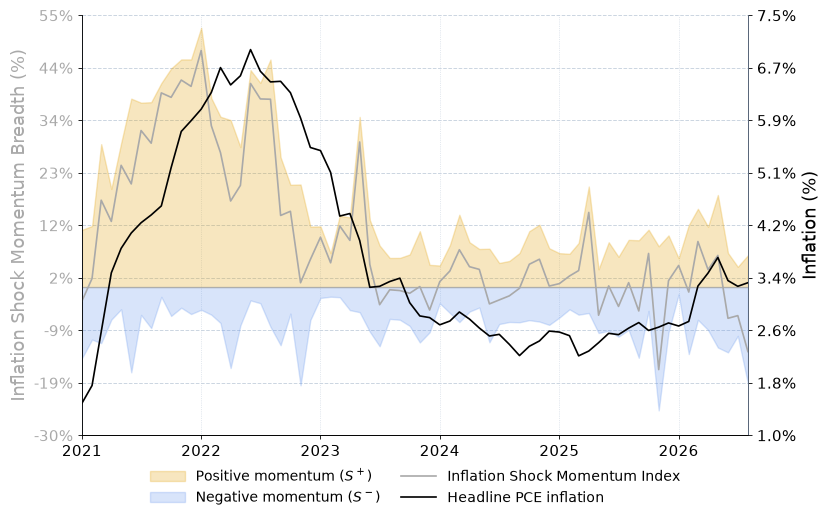

In [41]:
# -------------------------------------------------------
# Figure: recent period only (2023–present)
# -------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(9, 6))
# 8 inches ≈ 1/3 of the original two-panel figure

ax2 = plot_panel(
    ax1,
    start=pd.Timestamp("2021-01-01"),
    end=df.index.max(),
    year_interval=1,
    n_intervals=8,
    left_step=5,
    right_step=0.5
)

# Axis labels
ax1.set_ylabel(
    "Inflation Shock Momentum Breadth (%)",
    color=COLORS["ismi"],
    fontsize=13
)

ax2.set_ylabel(
    "Inflation (%)",
    color=COLORS["headline"],
    fontsize=13
)

# Legend
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=2,
    frameon=False,
    fontsize=10,
    columnspacing=1.5,
    handlelength=2.5
)


fig.subplots_adjust(
    top=0.82,
    bottom=0.12,
    left=0.13,
    right=0.87
)

plt.show()

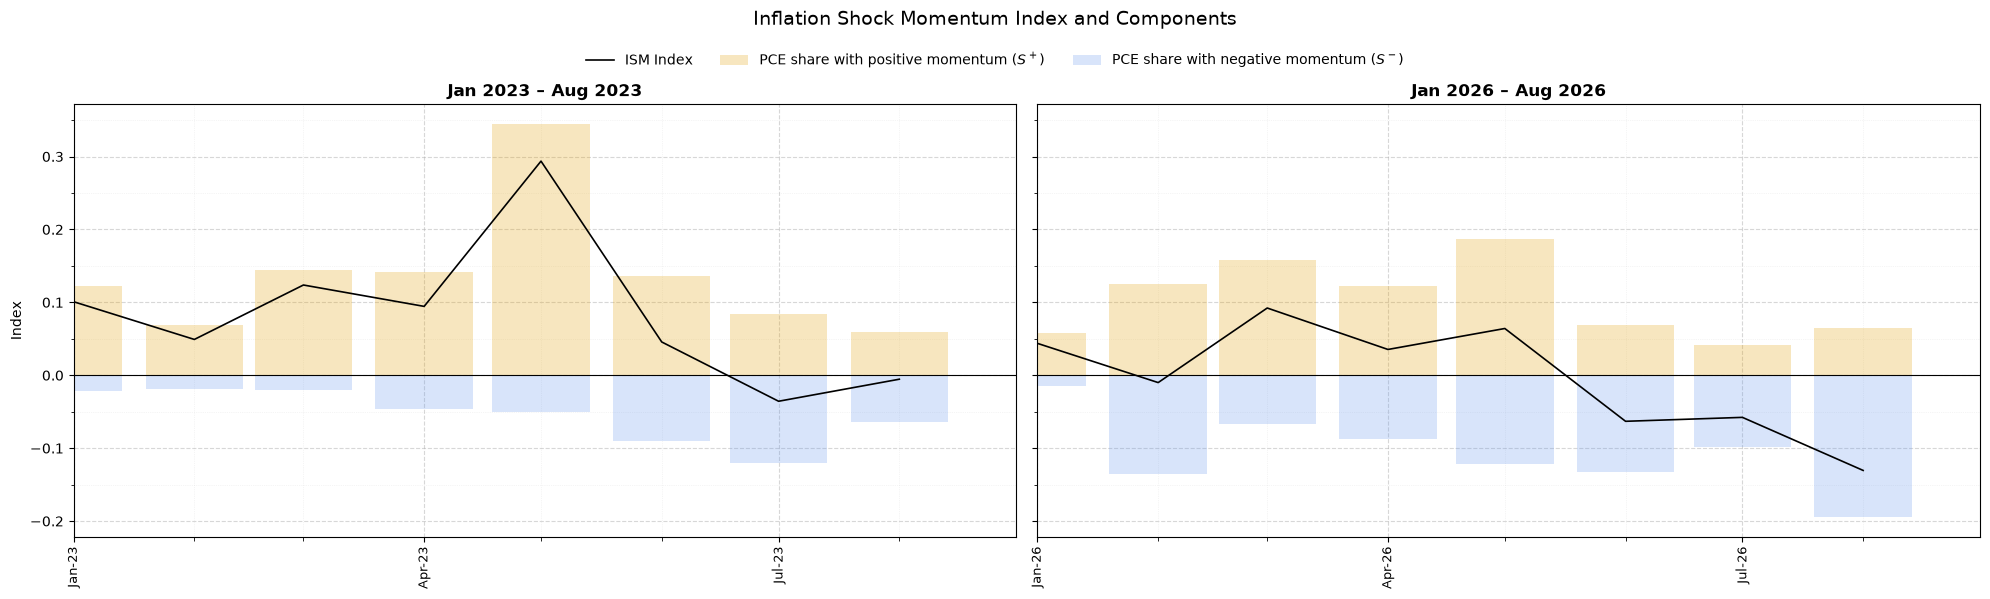

In [42]:
# Periods
COLORS = {
    "positive": "#E39F00D3",
    "negative": "cornflowerblue",
    "ismi":     "darkgrey",
    "headline": "black",
    "grid":     "#CBD5E1",
}

periods = [
    ("2023-01-01", "2023-08-31"),
    ("2026-01-01", "2026-08-31")
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(20, 6),
    sharey=True
)

for ax, (start, end) in zip(axes, periods):

    df = dfIsmi.loc[start:end]

    # Positive contributions
    ax.bar(
        df.index,
        df["ISMI+"],
        width=25,
        color=COLORS["positive"],
        alpha=0.25,
        label=r"PCE share with positive momentum ($S^+$)",
        zorder=2
    )

    # Negative contributions
    ax.bar(
        df.index,
        -df["ISMI-"],
        width=25,
        color=COLORS["negative"],
        alpha=0.25,
        label=r"PCE share with negative momentum ($S^-$)",
        zorder=2
    )

    # ISMI line
    ax.plot(
        df.index,
        df["ISMIndex"],
        color="black",
        linewidth=1.2,
        label="ISM Index",
        zorder=3
    )

    # Zero line
    ax.axhline(0, color="black", linewidth=0.8)

    # Titles and limits
    ax.set_title(
        f"{pd.Timestamp(start):%b %Y} – {pd.Timestamp(end):%b %Y}",
        fontsize=12,
        fontweight="bold"
    )
    ax.set_xlim(pd.Timestamp(start), pd.Timestamp(end))

    # X-axis: labels every 3 months, monthly grid
    ax.xaxis.set_major_locator(
        mdates.MonthLocator(bymonth=[1, 4, 7, 10])
    )
    ax.xaxis.set_minor_locator(
        mdates.MonthLocator(interval=1)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%b-%y")
    )

    ax.tick_params(axis="x", which="major", rotation=90, labelsize=9)
    ax.tick_params(axis="x", which="minor", length=3)

    # Y-axis: major 0.1, minor 0.05
    ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))

    # Major grid
    ax.grid(
        which="major",
        axis="both",
        linestyle="--",
        linewidth=0.8,
        alpha=0.5,
        zorder=0
    )

    # Minor grid
    ax.grid(
        which="minor",
        axis="both",
        linestyle=":",
        linewidth=0.5,
        alpha=0.25,
        zorder=0
    )
    

    ax.set_axisbelow(True)

# Common Y-axis label
axes[0].set_ylabel("Index")

# Common legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=3,
    frameon=False
)

# Main title
fig.suptitle(
    "Inflation Shock Momentum Index and Components",
    fontsize=14,
    y=0.99
)

# Layout
fig.tight_layout(rect=[0, 0, 1, 0.95])

plt.show()


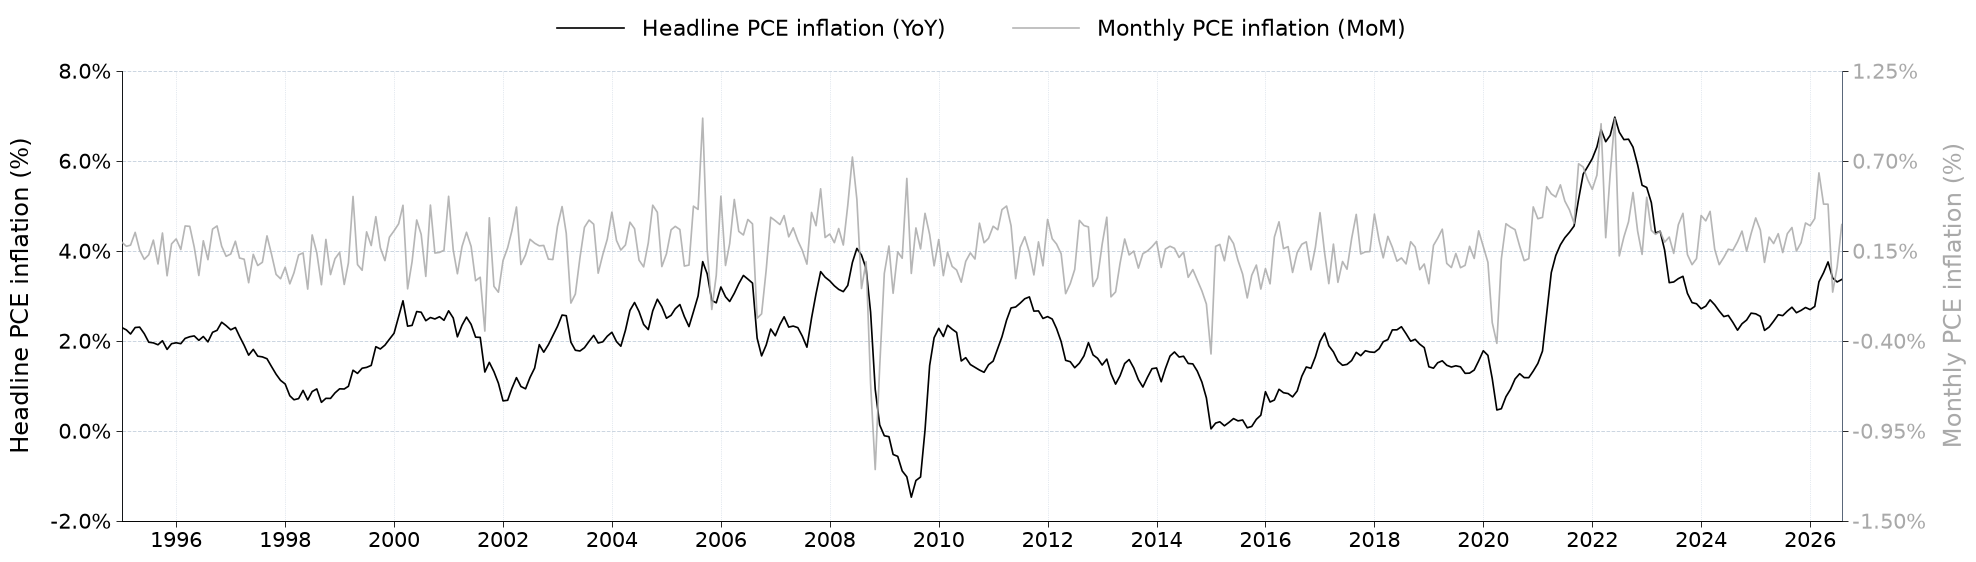

In [43]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# -------------------------------------------------------
# Colors
# -------------------------------------------------------
COLORS = {
    "positive": "#E39F00D3",
    "negative": "black" , #"royalblue"
    "monthly": "darkgrey",
    "headline": "black",
    "grid": "#CBD5E1",
}

# -------------------------------------------------------
# Data
# -------------------------------------------------------
df = dfFilterResults.loc["1995-01-01":].sort_index()

xAxis = df.index

# Inflation in percentage points
headline = df["headlinePce"] * 100
monthly = df["monthlyPce"] * 100

# -------------------------------------------------------
# Figure
# -------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(20, 6))
ax2 = ax1.twinx()

# Left axis: annual headline inflation
ax1.plot(
    xAxis,
    headline,
    label="Headline PCE inflation (YoY)",
    color=COLORS["negative"],
    linewidth=1.2,
    zorder=4
)

# Right axis: monthly inflation
ax2.plot(
    xAxis,
    monthly,
    label="Monthly PCE inflation (MoM)",
    color=COLORS["monthly"],
    linewidth=1.2,
    alpha=0.85,
    zorder=3
)

# -------------------------------------------------------
# Axis limits with 5% padding
# -------------------------------------------------------
def nice_limits(values, padding=0.05, step=1):

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    vmin = values.min()
    vmax = values.max()

    span = vmax - vmin

    if span == 0:
        span = max(abs(vmax), 1.0)

    lower = np.floor(
        (vmin - padding * span) / step
    ) * step

    upper = np.ceil(
        (vmax + padding * span) / step
    ) * step

    return lower, upper


# Left axis: annual inflation
ymin1, ymax1 = nice_limits(
    headline,
    padding=0.05,
    step=1
)

# Right axis: monthly inflation
ymin2, ymax2 = nice_limits(
    monthly,
    padding=0.05,
    step=0.25
)

ax1.set_ylim(ymin1, ymax1)
ax2.set_ylim(ymin2, ymax2)

# -------------------------------------------------------
# Aligned horizontal gridlines
# -------------------------------------------------------
n_intervals = 5

ticks_left = np.linspace(
    ymin1, ymax1, n_intervals + 1
)

ticks_right = np.linspace(
    ymin2, ymax2, n_intervals + 1
)

ax1.set_yticks(ticks_left)
ax2.set_yticks(ticks_right)

# Tick formatting
ax1.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:.1f}%")
)

ax2.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:.2f}%")
)

# -------------------------------------------------------
# Axis labels
# -------------------------------------------------------
ax1.set_ylabel(
    "Headline PCE inflation (%)",
    fontsize=17,
    color=COLORS["negative"],
    labelpad=12
)

ax2.set_ylabel(
    "Monthly PCE inflation (%)",
    fontsize=17,
    color=COLORS["monthly"],
    labelpad=12
)

# -------------------------------------------------------
# X-axis: one tick every 2 years
# -------------------------------------------------------
ax1.set_xlim(
    pd.Timestamp("1995-01-01"),
    df.index.max()
)

ax1.xaxis.set_major_locator(
    mdates.YearLocator(2)
)

ax1.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

# -------------------------------------------------------
# Grid
# -------------------------------------------------------
ax1.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    color=COLORS["grid"]
)

ax1.grid(
    axis="x",
    linestyle=":",
    linewidth=0.5,
    color=COLORS["grid"]
)

ax1.set_axisbelow(True)
ax2.grid(False)

# # -------------------------------------------------------
# # Zero lines
# # -------------------------------------------------------
# ax1.axhline(
#     0,
#     color=COLORS["negative"],
#     linewidth=0.8,
#     alpha=0.6
# )

# ax2.axhline(
#     0,
#     color=COLORS["monthly"],
#     linewidth=0.8,
#     alpha=0.6
# )

# -------------------------------------------------------
# Spines
# -------------------------------------------------------
for ax in (ax1, ax2):

    ax.spines["top"].set_visible(False)

    ax.spines["bottom"].set_linewidth(0.6)
    ax.spines["left"].set_linewidth(0.6)
    ax.spines["right"].set_linewidth(0.6)

ax1.spines["left"].set_color("#64748B")
ax2.spines["right"].set_color("#64748B")

# -------------------------------------------------------
# Tick styling
# -------------------------------------------------------
ax1.tick_params(
    axis="x",
    labelsize=15,
    rotation=0,
    width=0.6,
    length=4
)

ax1.tick_params(
    axis="y",
    labelsize=15,
    labelcolor=COLORS["negative"],
    width=0.6,
    length=4
)

ax2.tick_params(
    axis="y",
    labelsize=15,
    labelcolor=COLORS["monthly"],
    width=0.6,
    length=4
)

# -------------------------------------------------------
# Combined legend
# -------------------------------------------------------
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

fig.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.99),
    ncol=2,
    frameon=False,
    fontsize=16,
    columnspacing=3,
    handlelength=3
)

# -------------------------------------------------------
# Layout
# -------------------------------------------------------
fig.subplots_adjust(
    top=0.87,
    bottom=0.12,
    left=0.07,
    right=0.93
)

plt.show()


# Chart 2

In [44]:
# # Last 12 observations
# recentIsmi = dfIsmi.tail(24)
# recentRho = dfFilterResults.tail(24)

# # ------------------------------------
# # Figure: 2/3 + 1/3
# # ------------------------------------
# fig, (ax1, ax2) = plt.subplots(
#     1, 2,
#     figsize=(20, 6),
#     gridspec_kw={"width_ratios": [2, 1]}
# )

# # ====================================
# # PANEL 1: Historical ISMI + inflation
# # ====================================
# ax1.plot(
#     dfIsmi.index,
#     dfIsmi["ISMIndex"].rolling(12).sum(),
#     color="black",
#     linewidth=1,
#     label="ISMI"
# )

# ax1.axhline(0, color="grey", linewidth=0.8)

# ax1.set_ylabel("ISMI")
# ax1.set_xlim(dfIsmi.index[0], dfIsmi.index.max())

# # Second Y-axis: headline inflation
# ax1b = ax1.twinx()

# ax1b.plot(
#     dfFilterResults.index,
#     dfFilterResults["headlinePce"].values*100,
#     color="darkgrey",
#     linewidth=1,
#     label="Headline inflation (YoY)",
#     zorder=5
# )

# ax1b.set_ylabel("Headline inflation (%)")

# # Dates every 6 months
# ax1.xaxis.set_major_locator(
#     mdates.MonthLocator(bymonth=[1, 7], bymonthday=1)
# )
# ax1.xaxis.set_major_formatter(
#     mdates.DateFormatter("%b-%y")
# )

# ax1.tick_params(axis="x", rotation=90, labelsize=8)

# # Major grids: X and Y
# ax1.grid(
#     True,
#     which="major",
#     axis="both",
#     linestyle="--",
#     alpha=0.25
# )

# ax1.set_title("ISMI and Headline Inflation")

# # Combined legend
# lines1, labels1 = ax1.get_legend_handles_labels()
# lines2, labels2 = ax1b.get_legend_handles_labels()

# ax1.legend(
#     lines1 + lines2,
#     labels1 + labels2,
#     loc="upper left"
# )

# # ====================================
# # PANEL 2: Last 12 months
# # ====================================
# ax2.bar(
#     recentIsmi.index,
#     recentIsmi["ISMI+"],
#     width=20,
#     color="darkslateblue",
#     alpha=0.65,
#     label=r"$S^+$"
# )

# ax2.bar(
#     recentIsmi.index,
#     -recentIsmi["ISMI-"],
#     width=20,
#     color="mediumslateblue",
#     alpha=0.65,
#     label=r"$S^-$"
# )

# ax2.plot(
#     recentIsmi.index,
#     recentIsmi["ISMIndex"],
#     color="black",
#     linewidth=1,
#     marker="o",
#     markersize=5,
#     label="ISMI",
#     zorder=3
# )

# ax2.axhline(0, color="grey", linewidth=0.8)

# # One tick per month
# ax2.xaxis.set_major_locator(
#     mdates.MonthLocator(interval=1)
# )
# ax2.xaxis.set_major_formatter(
#     mdates.DateFormatter("%b-%y")
# )

# ax2.set_xlim(
#     recentIsmi.index.min() - pd.Timedelta(days=12),
#     recentIsmi.index.max() + pd.Timedelta(days=12)
# )

# ax2.tick_params(axis="x", rotation=90, labelsize=9)
# ax2.set_ylabel("ISMI components")

# ax2.grid(
#     True,
#     which="major",
#     axis="both",
#     linestyle="--",
#     alpha=0.25
# )

# ax2.set_title("ISMI Decomposition — Last 12 Months")
# ax2.legend(loc="upper left", ncol=3)

# # ------------------------------------
# # Formatting
# # ------------------------------------
# for ax in (ax1, ax2):
#     ax.set_axisbelow(True)
#     ax.spines["top"].set_visible(False)

# fig.tight_layout()
# plt.show()

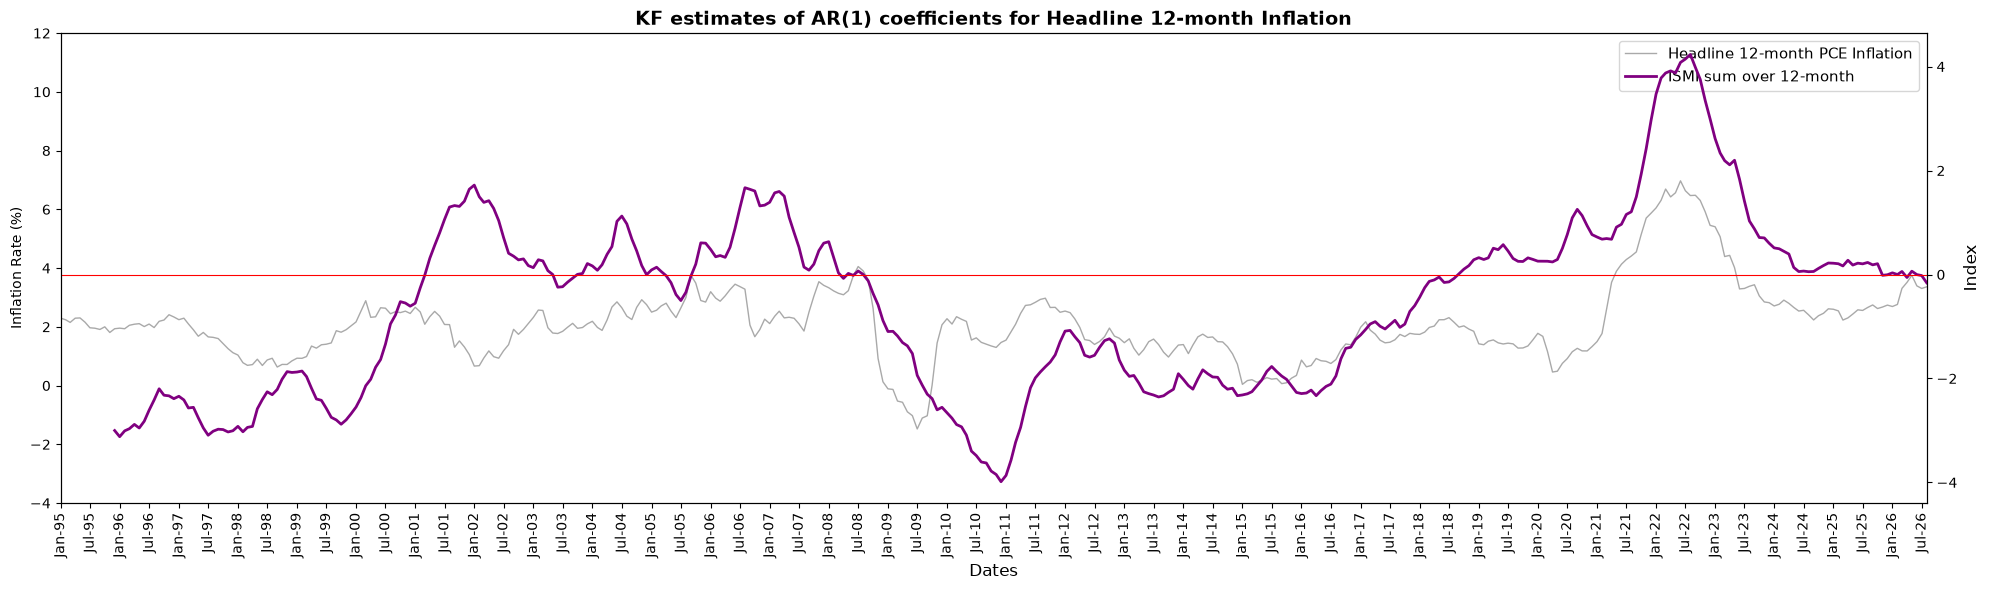

In [45]:
# 12-month ISMI and headline inflation
xAxis = dfFilterResults.index
pi = dfFilterResults["headlinePce"]
_, ax1 = plt.subplots(figsize=(20, 6))

# --- Left axis (headline inflation - 12-month) ---
ax1.plot(
    xAxis,
    pi*100,
    label=f"Headline 12-month PCE Inflation",
    color="darkgrey",
    linewidth=1
)

ax1.set_xlabel("Dates", fontsize=12)
ax1.set_ylabel(f"Inflation Rate (%)")
ax1.set_ylim(-4, 12)

# X-axis
ax1.set_xlim(
    pd.Timestamp("1995-01-01"),
    dfFilterResults.index.max()
)

ax1.xaxis.set_major_locator(
    mdates.MonthLocator(bymonth=[1, 7], bymonthday=1)
)
ax1.xaxis.set_major_formatter(
    mdates.DateFormatter("%b-%y")
)

ax1.tick_params(axis="x", rotation=90)

# --- Right axis (ISMI sum coefficients) ---
ax2 = ax1.twinx()

ax2.plot(
    xAxis,
    dfIsmi["ISMIndex"].rolling(12).sum(),
    label="ISMI sum over 12-month",
    color="purple",
    linewidth=2
)

ax2.set_ylabel("Index", fontsize=12)
# ax2.set_ylim(0.8, 1.2)
ax2.tick_params(axis="y")

ax2.axhline(0, color="red", linewidth=0.8)


# --- Title, legend ---
plt.title(f"KF estimates of AR(1) coefficients for Headline 12-month Inflation", fontsize=14, fontweight="bold")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best", fontsize=11)

plt.tight_layout()
plt.show()

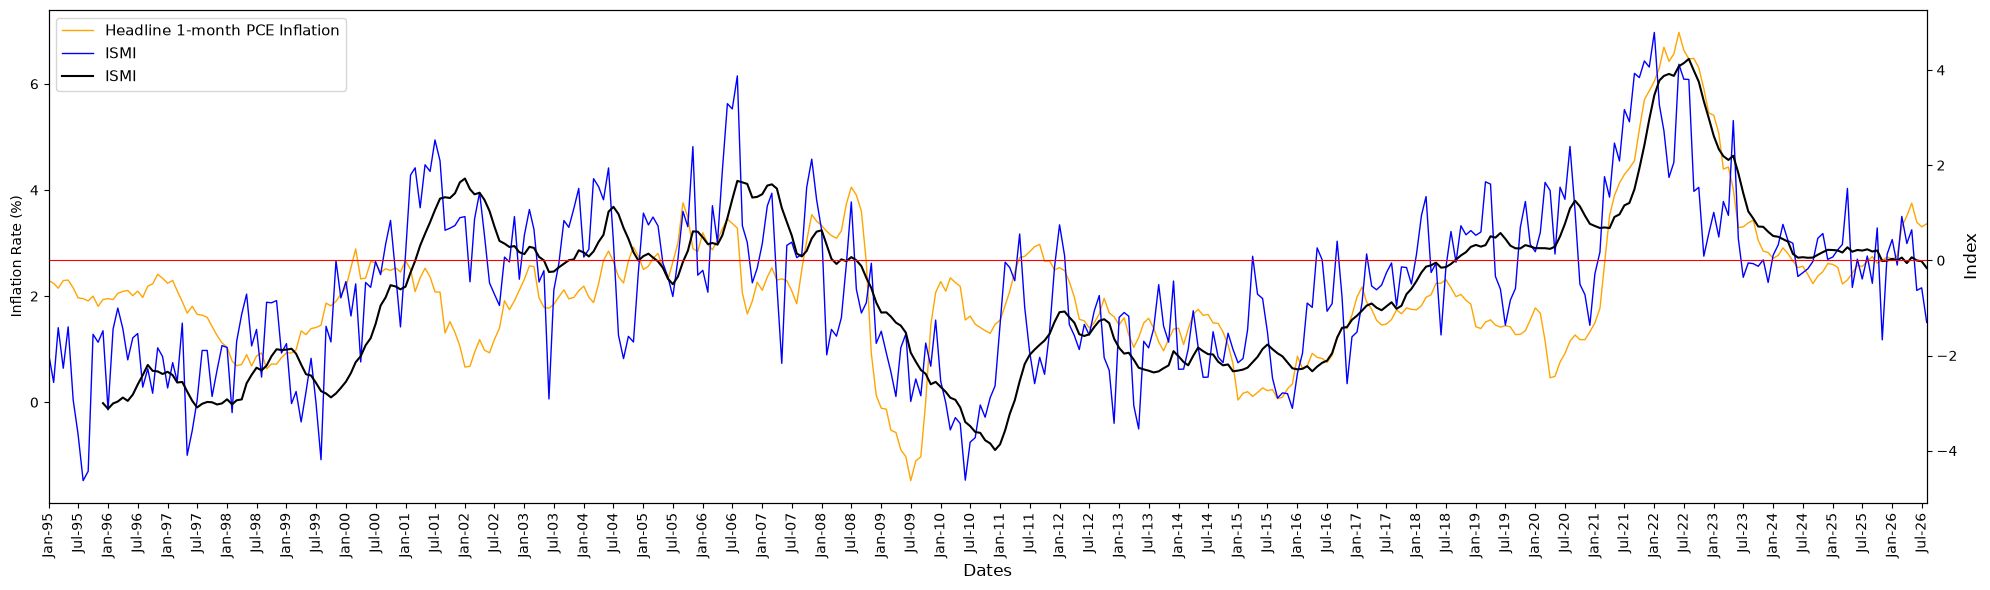

In [46]:
# 12-month ISMI and headline inflation
xAxis = dfFilterResults.index
pi = dfFilterResults["headlinePce"]
_, ax1 = plt.subplots(figsize=(20, 6))

# --- Left axis (headline inflation - 12-month) ---
ax1.plot(
    xAxis,
    pi*100,
    label=f"Headline 1-month PCE Inflation",
    color="orange",
    linewidth=1
)

ax1.set_xlabel("Dates", fontsize=12)
ax1.set_ylabel(f"Inflation Rate (%)")

# X-axis
ax1.set_xlim(
    pd.Timestamp("1995-01-01"),
    dfFilterResults.index.max()
)

ax1.xaxis.set_major_locator(
    mdates.MonthLocator(bymonth=[1, 7], bymonthday=1)
)
ax1.xaxis.set_major_formatter(
    mdates.DateFormatter("%b-%y")
)

ax1.tick_params(axis="x", rotation=90)

# --- Right axis (ISMI sum coefficients) ---
ax2 = ax1.twinx()

ax2.plot(
    xAxis,
    dfIsmi["ISMIndex"]*10,
    label="ISMI",
    color="blue",
    linewidth=1
)

ax2.plot(
    xAxis,
    dfIsmi["ISMIndex"].rolling(12).sum(),
    label="ISMI",
    color="black",
    linewidth=1.5
)

ax2.set_ylabel("Index", fontsize=12)
# ax2.set_ylim(0.8, 1.2)
ax2.tick_params(axis="y")

ax2.axhline(0, color="red", linewidth=0.8)


# --- Title, legend ---

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best", fontsize=11)

plt.tight_layout()
plt.show()

# Chart 3

In [47]:
# # Rolling persistance coefficient since 1959 against headline PCE
# xAxis = dfFilterResults.index
# lag = 1
# results = dfFilterResults
# pi = dfFilterResults["headlinePce"]

# Rho = dfFilterResults["Rho"].rolling(12).sum() #results["Rho"]
# stdState = np.sqrt(results["StateMse"])
# uB = Rho+1.645*stdState
# lB = Rho-1.645*stdState
# _, ax1 = plt.subplots(figsize=(20, 6))

# # --- Left axis (HICP inflation - 12-month) ---
# ax1.plot(
#     xAxis,
#     pi*100,
#     label=f"Headline {lag}-month inflation",
#     color="darkgrey",
#     linewidth=1
# )

# ax1.set_xlabel("Dates", fontsize=12)
# ax1.set_ylabel(f"Headline {lag}-month inflation (%)")
# # ax1.set_ylim(-4, 12)
# ax1.grid(True, linestyle="--", alpha=0.5)

# # X-axis
# ax1.set_xlim(
#     pd.Timestamp("1995-01-01"),
#     dfFilterResults.index.max()
# )

# ax1.xaxis.set_major_locator(
#     mdates.MonthLocator(bymonth=[1, 7], bymonthday=1)
# )
# ax1.xaxis.set_major_formatter(
#     mdates.DateFormatter("%b-%y")
# )

# ax1.tick_params(axis="x", rotation=90)

# # --- Right axis (AR coefficients) ---
# ax2 = ax1.twinx()

# ax2.plot(
#     xAxis,
#     Rho,
#     label=r'$\hat \rho_t$ coefficient',
#     color="purple",
#     linewidth=2
# )

# # IC
# ax2.fill_between(
#     xAxis,
#     lB,
#     uB,
#     color="purple",
#     alpha=0.05,
#     label="Conditional IC (90%)"
# )

# ax2.set_ylabel("AR(1) coefficients value", fontsize=12)
# # ax2.set_ylim(0.8, 1.2)
# ax2.tick_params(axis="y")

# ax2.axhline(12*0.48, color="purple", linewidth=0.8, label = r"$\bar \rho$ long-term persistence")


# # --- Title, legend ---
# plt.title(f"KF estimates of AR(1) coefficients for Headline {lag}-month Inflation", fontsize=14, fontweight="bold")

# lines1, labels1 = ax1.get_legend_handles_labels()
# lines2, labels2 = ax2.get_legend_handles_labels()
# ax1.legend(lines1 + lines2, labels1 + labels2, loc="best", fontsize=11)

# plt.tight_layout()
# plt.show()

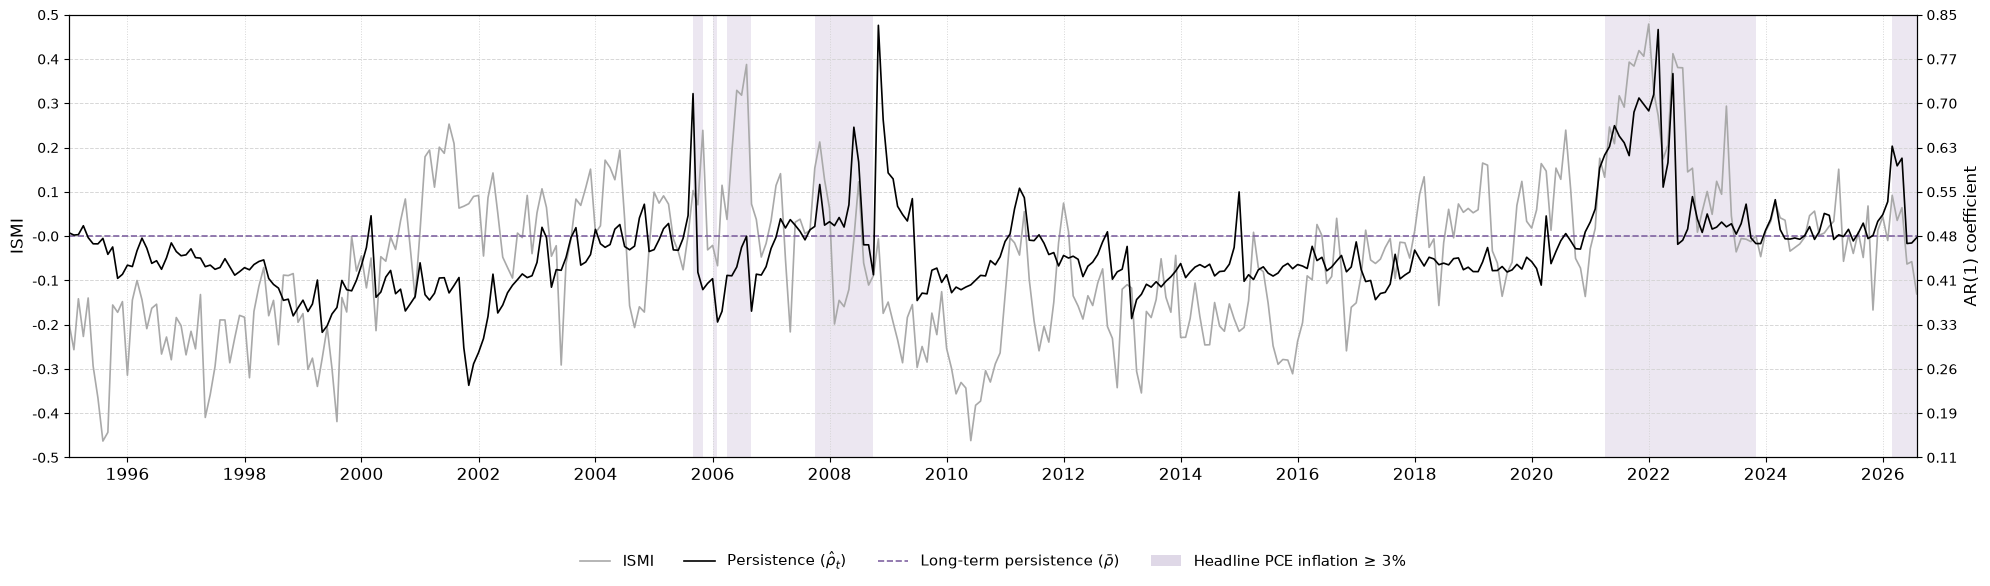

In [48]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, FormatStrFormatter

# --- Colors ---
colors = {
    "ismi": "darkgrey",
    "rho": "black",
    "rho_lt": "#8064A2",
    "regime": "#8064A2"
}

# --- Common x-axis settings ---
x_min = pd.Timestamp("1995-01-01")
x_max = dfFilterResults.index.max()

# --- Data ---
xAxis = dfFilterResults.index
Rho = dfFilterResults["Rho"]
inflation = dfFilterResults["headlinePce"] * 100

fig, ax1 = plt.subplots(figsize=(20, 6))
ax2 = ax1.twinx()

# --- Left axis: ISMI ---
ax1.plot(
    dfIsmi.index,
    dfIsmi["ISMIndex"],
    label="ISMI",
    color=colors["ismi"],
    linewidth=1.2,
    zorder=3
)

ax1.set_ylabel("ISMI", fontsize=12)

# --- Left axis: ISMI ---
ax1.set_ylim(-0.5, 0.5)

ticks_ismi = np.arange(-0.5, 0.51, 0.1)
ax1.yaxis.set_major_locator(FixedLocator(ticks_ismi))
ax1.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))

# --- Right axis: Persistence ---
ax2.plot(
    xAxis,
    Rho,
    label=r"Persistence ($\hat{\rho}_t$)",
    color=colors["rho"],
    linewidth=1.2,
    zorder=3
)

ax2.axhline(
    0.48,
    color=colors["rho_lt"],
    linewidth=1.2,
    linestyle="--",
    label=r"Long-term persistence ($\bar{\rho}$)"
)

ax2.set_ylabel("AR(1) coefficient", fontsize=12)

# --- Right axis: Persistence ---
rho_center = 0.48

# Symmetric bounds around long-term persistence
rho_valid = Rho.loc[x_min:x_max].dropna()

rho_half_range = max(
    abs(rho_valid.min() - rho_center),
    abs(rho_valid.max() - rho_center)
)

# Add a small margin
rho_half_range *= 1.05

ax2.set_ylim(
    rho_center - rho_half_range,
    rho_center + rho_half_range
)

# Same number of ticks as ISMI
ticks_rho = np.linspace(
    rho_center - rho_half_range,
    rho_center + rho_half_range,
    len(ticks_ismi)
)

ax2.yaxis.set_major_locator(FixedLocator(ticks_rho))
ax2.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

# --- Inflation regimes: Headline PCE >= 3% ---
high_inflation = inflation.ge(3).fillna(False)

starts = high_inflation & ~high_inflation.shift(
    1, fill_value=False
)
ends = high_inflation & ~high_inflation.shift(
    -1, fill_value=False
)

for start, end in zip(
    inflation.index[starts],
    inflation.index[ends]
):
    ax1.axvspan(
        start,
        end + pd.offsets.MonthEnd(1),
        facecolor=colors["regime"],
        alpha=0.15,
        edgecolor="none",
        zorder=0
    )

# --- Common x-axis ---
# X-axis
ax1.set_xlim(x_min, x_max)

ax1.xaxis.set_major_locator(
    mdates.YearLocator(2)
)

ax1.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

ax1.tick_params(
    axis="x",
    rotation=0,
    labelsize=12
)

# --- Grid ---
ax1.set_axisbelow(True)
ax2.set_axisbelow(True)

# Horizontal gridlines (left axis only)
ax1.grid(
    True,
    axis="y",
    linestyle="--",
    linewidth=0.7,
    color="lightgrey",
    alpha=0.9
)

# Vertical gridlines (every 2 years)
ax1.grid(
    True,
    axis="x",
    linestyle=":",
    linewidth=0.7,
    color="lightgrey",
    alpha=0.9
)

# Disable grid on secondary axis
ax2.grid(False)

# Make secondary axis background transparent
ax2.patch.set_visible(False)

# --- Legend ---
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

regime_patch = Patch(
    facecolor=colors["regime"],
    alpha=0.25,
    label="Headline PCE inflation ≥ 3%"
)

ax1.legend(
    lines1 + lines2 + [regime_patch],
    labels1 + labels2 + ["Headline PCE inflation ≥ 3%"],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=4,
    frameon=False,
    fontsize=11
)

plt.tight_layout()
plt.show()

In [49]:
mask = (dfFilterResults["headlinePce"] >= 0.03)
dfFilterResults[mask]

,Y,FittedY,Err,StateMse,centeredState,Rho,KalmanGain,LogLikelihood,monthlyPce,headlinePce,piStar
Date,,,,,,,,,,,
2005-09-01,0.009604,0.003823,0.006608,0.023116,0.235921,0.715891,31.057543,-1.001474,0.009604,0.037585,2.341762
2005-10-01,0.001598,0.004977,-0.005992,0.014165,-0.059690,0.420280,45.399147,1.775443,0.001598,0.034898,2.312110
2006-01-01,0.004836,0.000940,0.003896,0.022628,-0.070430,0.409540,0.000000,2.907899,0.004836,0.031953,2.236043
2006-04-01,0.004634,0.001744,0.002981,0.024350,-0.065017,0.414953,15.733874,3.986869,0.004634,0.030557,2.132261
2006-05-01,0.002683,0.002860,-0.000211,0.021999,-0.065693,0.414277,34.020599,5.348022,0.002683,0.032676,2.119568
2006-06-01,0.002463,0.002091,0.000393,0.022882,-0.051070,0.428900,20.483060,5.387423,0.002463,0.034514,2.111180
2006-07-01,0.003412,0.002076,0.001402,0.023730,-0.018618,0.461352,19.500301,5.103089,0.003412,0.033699,2.106176
2006-08-01,0.003141,0.002577,0.000621,0.023297,-0.000290,0.479680,26.521336,5.334151,0.003141,0.032814,2.093385
2007-10-01,0.003028,0.002847,0.000206,0.025046,0.016073,0.496043,32.128036,5.367929,0.003028,0.030417,2.168620


# Rolling correlation

In [50]:
RolCorrel = dfIsmi["ISMIndex"].rolling(window=12).corr(dfFilterResults["Rho"])

In [51]:
# np.corrcoef(dfIsmi["ISMIndex"].values, dfFilterResults["Rho"].values)

In [52]:
# # Correlation conditionnelle
# mask = (dfFilterResults["headlinePce"] >= 0.03)
# A = dfIsmi.loc[mask,"ISMIndex"].values
# B = dfFilterResults.loc[mask, "headlinePce"].values
# np.corrcoef(A, B)

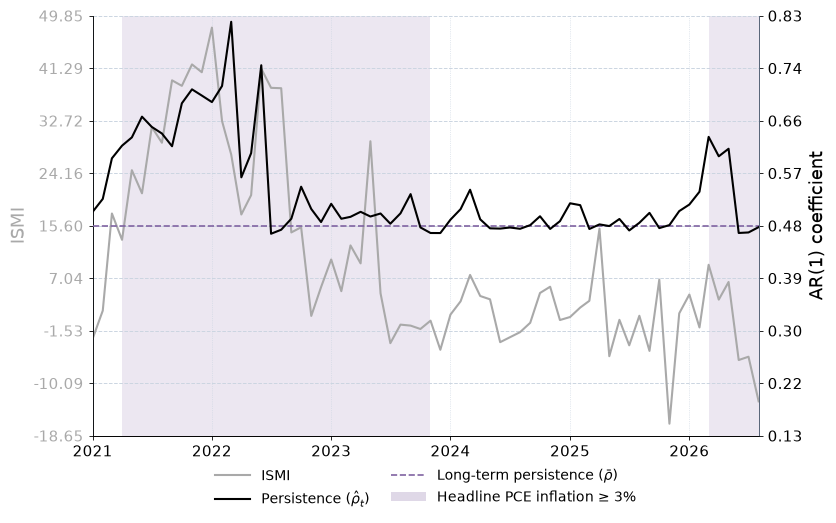

In [53]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, FormatStrFormatter

# -------------------------------------------------------
# Colors
# -------------------------------------------------------
colors = {
    "ismi": "darkgrey",
    "rho": "black",
    "rho_lt": "#8064A2",
    "regime": "#8064A2",
    "grid": "#CBD5E1"
}

# -------------------------------------------------------
# Dates
# -------------------------------------------------------
x_min = pd.Timestamp("2021-01-01")
x_max = dfFilterResults.index.max()

# -------------------------------------------------------
# Data: recent period only
# -------------------------------------------------------
df_recent = dfFilterResults.loc[x_min:x_max].sort_index()
df_ismi_recent = dfIsmi.loc[x_min:x_max].sort_index()

Rho = df_recent["Rho"]
inflation = df_recent["headlinePce"] * 100
ismi = df_ismi_recent["ISMIndex"] * 100

rho_center = 0.48

# -------------------------------------------------------
# Figure
# -------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(9, 6))
ax2 = ax1.twinx()

# -------------------------------------------------------
# Left axis: ISMI
# -------------------------------------------------------
ax1.plot(
    df_ismi_recent.index,
    ismi,
    label="ISMI",
    color=colors["ismi"],
    linewidth=1.5,
    zorder=3
)

ax1.set_ylabel(
    "ISMI",
    fontsize=13,
    color=colors["ismi"]
)

# Limits adapted to recent observations
ismi_valid = ismi.dropna()

ismi_min = min(ismi_valid.min(), 0)
ismi_max = max(ismi_valid.max(), 0)

ismi_range = ismi_max - ismi_min
ismi_padding = 0.03 * ismi_range

ymin1 = np.floor(
    (ismi_min - ismi_padding) / 0.05
) * 0.05

ymax1 = np.ceil(
    (ismi_max + ismi_padding) / 0.05
) * 0.05

ax1.set_ylim(ymin1, ymax1)

# -------------------------------------------------------
# Right axis: Persistence
# -------------------------------------------------------
ax2.plot(
    df_recent.index,
    Rho,
    label=r"Persistence ($\hat{\rho}_t$)",
    color=colors["rho"],
    linewidth=1.5,
    zorder=4
)

ax2.axhline(
    rho_center,
    color=colors["rho_lt"],
    linewidth=1.2,
    linestyle="--",
    label=r"Long-term persistence ($\bar{\rho}$)",
    zorder=3
)

ax2.set_ylabel(
    "AR(1) coefficient",
    fontsize=13,
    color=colors["rho"]
)

# Symmetric bounds around long-term persistence
rho_valid = Rho.dropna()

rho_half_range = max(
    abs(rho_valid.min() - rho_center),
    abs(rho_valid.max() - rho_center)
)

# Small padding
rho_half_range *= 1.03

ax2.set_ylim(
    rho_center - rho_half_range,
    rho_center + rho_half_range
)

# -------------------------------------------------------
# Perfectly aligned horizontal gridlines
# -------------------------------------------------------
n_intervals = 8

ticks_ismi = np.linspace(
    ymin1,
    ymax1,
    n_intervals + 1
)

ticks_rho = np.linspace(
    rho_center - rho_half_range,
    rho_center + rho_half_range,
    n_intervals + 1
)

ax1.yaxis.set_major_locator(
    FixedLocator(ticks_ismi)
)

ax2.yaxis.set_major_locator(
    FixedLocator(ticks_rho)
)

ax1.yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)

ax2.yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)

# -------------------------------------------------------
# Inflation regimes: Headline PCE >= 3%
# -------------------------------------------------------
high_inflation = inflation.ge(3).fillna(False)

starts = high_inflation & ~high_inflation.shift(
    1, fill_value=False
)

ends = high_inflation & ~high_inflation.shift(
    -1, fill_value=False
)

for start, end in zip(
    inflation.index[starts],
    inflation.index[ends]
):
    ax1.axvspan(
        start,
        end + pd.offsets.MonthEnd(1),
        facecolor=colors["regime"],
        alpha=0.15,
        edgecolor="none",
        zorder=0
    )

# -------------------------------------------------------
# X-axis: annual ticks
# -------------------------------------------------------
ax1.set_xlim(x_min, x_max)

ax1.xaxis.set_major_locator(
    mdates.YearLocator(1)
)

ax1.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

ax1.tick_params(
    axis="x",
    rotation=0,
    labelsize=12
)

# -------------------------------------------------------
# Grid
# -------------------------------------------------------
ax1.set_axisbelow(True)

ax1.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    color=colors["grid"]
)

ax1.grid(
    axis="x",
    linestyle=":",
    linewidth=0.5,
    color=colors["grid"]
)

ax2.grid(False)
ax2.patch.set_visible(False)

# -------------------------------------------------------
# Styling
# -------------------------------------------------------
for ax in (ax1, ax2):

    ax.spines["top"].set_visible(False)

    for side in ["bottom", "left", "right"]:
        ax.spines[side].set_linewidth(0.6)

    ax.tick_params(
        axis="both",
        which="major",
        width=0.6,
        length=3,
        labelsize=11
    )

ax1.spines["left"].set_color("#64748B")
ax2.spines["right"].set_color("#64748B")

ax1.tick_params(
    axis="y",
    labelcolor=colors["ismi"]
)

ax2.tick_params(
    axis="y",
    labelcolor=colors["rho"]
)

# -------------------------------------------------------
# Legend
# -------------------------------------------------------
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

regime_patch = Patch(
    facecolor=colors["regime"],
    alpha=0.25,
    label="Headline PCE inflation ≥ 3%"
)

ax1.legend(
    lines1 + lines2 + [regime_patch],
    labels1 + labels2 + ["Headline PCE inflation ≥ 3%"],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=2,
    frameon=False,
    fontsize=10,
    columnspacing=1.5,
    handlelength=2.5
)

# -------------------------------------------------------
# Layout
# -------------------------------------------------------
fig.subplots_adjust(
    top=0.82,
    bottom=0.12,
    left=0.13,
    right=0.87
)

plt.show()


# Chart 5

In [39]:
mask = ((dfIsmi.index >= "1998-01-01 00:00:00") & (dfIsmi.index <= "2000-01-01 00:00:00"))
dfFilterResults.loc[mask,"headlinePce"].max() #.max()
dfFilterResults #[mask] #.max()

,Y,FittedY,Err,StateMse,centeredState,Rho,KalmanGain,LogLikelihood,monthlyPce,headlinePce,piStar
Date,,,,,,,,,,,
1995-01-01,0.002028,0.001252,0.000779,0.033492,0.005594,0.485564,7.176229,5.336840,0.002028,0.022950,NaN
1995-02-01,0.001771,0.001917,-0.000153,0.032047,0.001720,0.481690,21.688666,5.413846,0.001771,0.022407,NaN
1995-03-01,0.001842,0.001795,0.000049,0.031292,0.002455,0.482425,18.494863,5.423021,0.001842,0.021500,NaN
1995-04-01,0.002624,0.001856,0.000795,0.030638,0.017186,0.497156,18.835246,5.320574,0.002624,0.022942,NaN
1995-05-01,0.001538,0.002193,-0.000702,0.029122,-0.002428,0.477542,25.498221,5.328748,0.001538,0.023027,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2026-04-01,0.004349,0.004674,-0.000436,0.019426,0.116364,0.596334,40.584694,5.269819,0.004349,0.035116,2.348595
2026-05-01,0.004345,0.003589,0.000862,0.019417,0.129016,0.608986,28.175761,5.265928,0.004345,0.037521,2.408486
2026-06-01,-0.001029,0.002973,-0.004560,0.019415,-0.012233,0.467737,28.149694,2.330373,-0.001029,0.033947,2.400341


In [40]:
dfIsmi

,ISMI+,ISMI-,ISMIndex,Personal consumption expenditures
TIME_PERIOD,,,,
1995-01-01,0.017190,0.213088,-0.195899,0.202807
1995-02-01,0.007612,0.264224,-0.256613,0.177119
1995-03-01,0.067066,0.208603,-0.141537,0.184228
1995-04-01,0.075000,0.301726,-0.226726,0.262384
1995-05-01,0.056534,0.196288,-0.139754,0.153848
...,...,...,...,...
2026-04-01,0.122158,0.086773,0.035386,0.434855
2026-05-01,0.186366,0.122225,0.064141,0.434496
2026-06-01,0.069004,0.132141,-0.063137,-0.102917


In [41]:
target = np.ones(dfFilterResults.shape[0])*0.02
abSpread = np.abs((target/dfFilterResults["headlinePce"].values)-1)


In [42]:
monthToTarget = np.log(abSpread)/dfFilterResults["Rho"].values

# Chart 4

In [43]:
# Average monthly inflation expectations
dfM = df.resample("MS").mean(numeric_only=True)

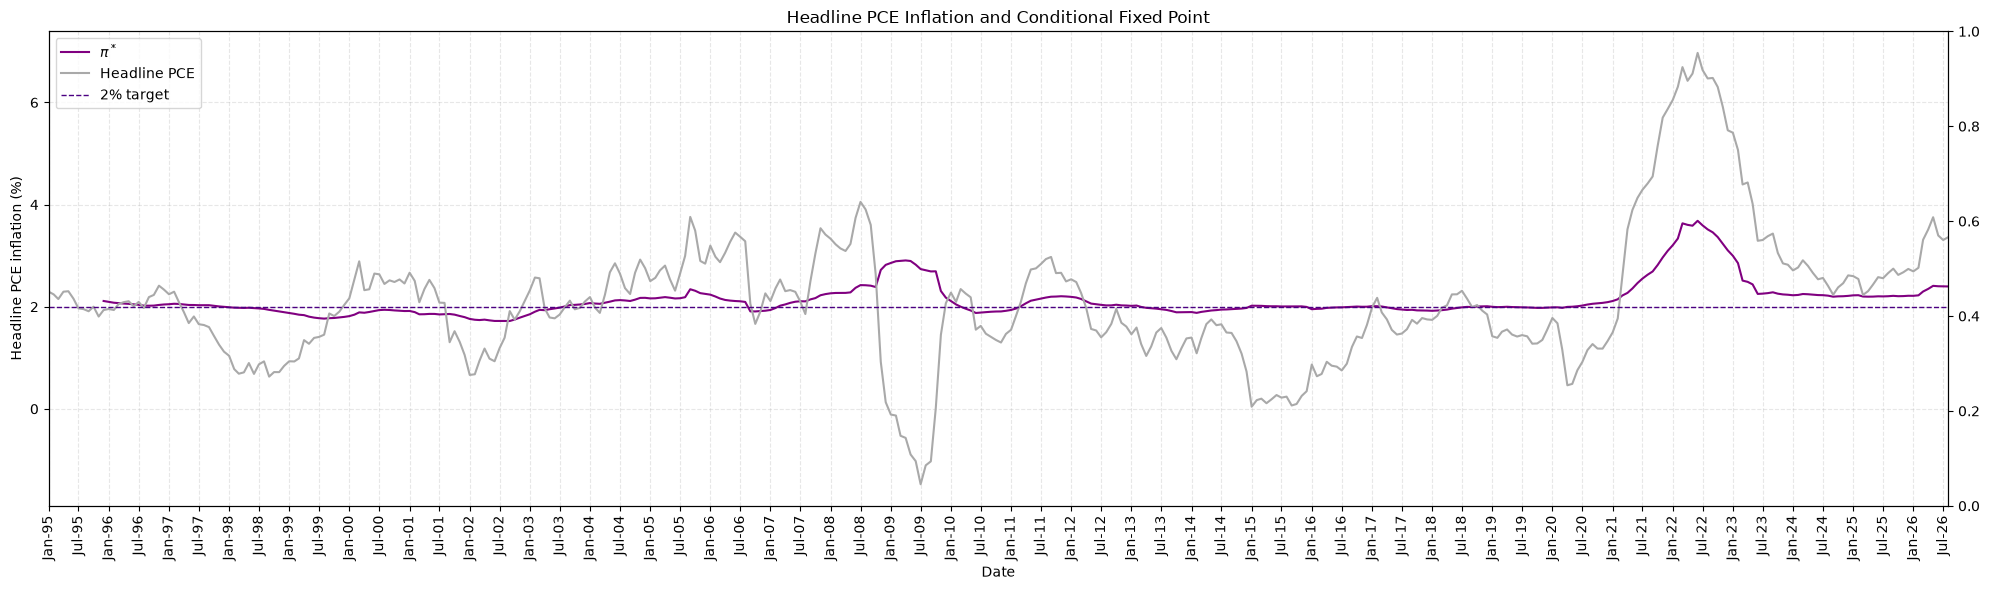

In [44]:
fig, ax1 = plt.subplots(figsize=(20, 6))
ax2 = ax1.twinx()
axes = [ax1, ax2]

# Left axis: Pi star
ax1.plot(
    dfFilterResults.index,
    dfFilterResults["piStar"],
    linewidth=1.5,
    color="purple",
    label=r"$\pi^*$"
)

# # 5y5y inflation expectations
# ax1.plot(
#     dfM.index,
#     dfM.values,
#     linewidth=1.5,
#     color="pink",
#     label="5y5y market-implied expectations"
# )

ax1.set_ylabel(r"Conditional fixed point ($\pi^*$)", color="purple")
ax1.tick_params(axis="y", labelcolor="purple")

# Right axis: Headline PCE
ax1.plot(
    dfFilterResults.index,
    dfFilterResults["headlinePce"] * 100,
    linewidth=1.5,
    color="darkgrey",
    label="Headline PCE"
)

# 2% target
ax1.axhline(
    y=2,
    linewidth=1,
    color="indigo",
    linestyle="--",
    label="2% target"
)

ax1.set_ylabel("Headline PCE inflation (%)", color="black")
ax1.tick_params(axis="y", labelcolor="black")

# X-axis
ax1.set_xlim(
    pd.Timestamp("1995-01-01"),
    dfFilterResults.index.max()
)

ax1.xaxis.set_major_locator(
    mdates.MonthLocator(bymonth=[1, 7], bymonthday=1)
)
ax1.xaxis.set_major_formatter(
    mdates.DateFormatter("%b-%y")
)

ax1.tick_params(axis="x", rotation=90)

# Labels and title
ax1.set_xlabel("Date")
ax1.set_title("Headline PCE Inflation and Conditional Fixed Point")

# Grid
ax1.grid(
    True,
    which="major",
    axis="both",
    linestyle="--",
    alpha=0.3
)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

# Add regimes...
# Fed Hawkish
for ax in axes:
    addHawkishRegimes(
        ax,
        starts,
        ends,
        color="purple",
        alpha=0.05
    )

plt.tight_layout()
plt.show()

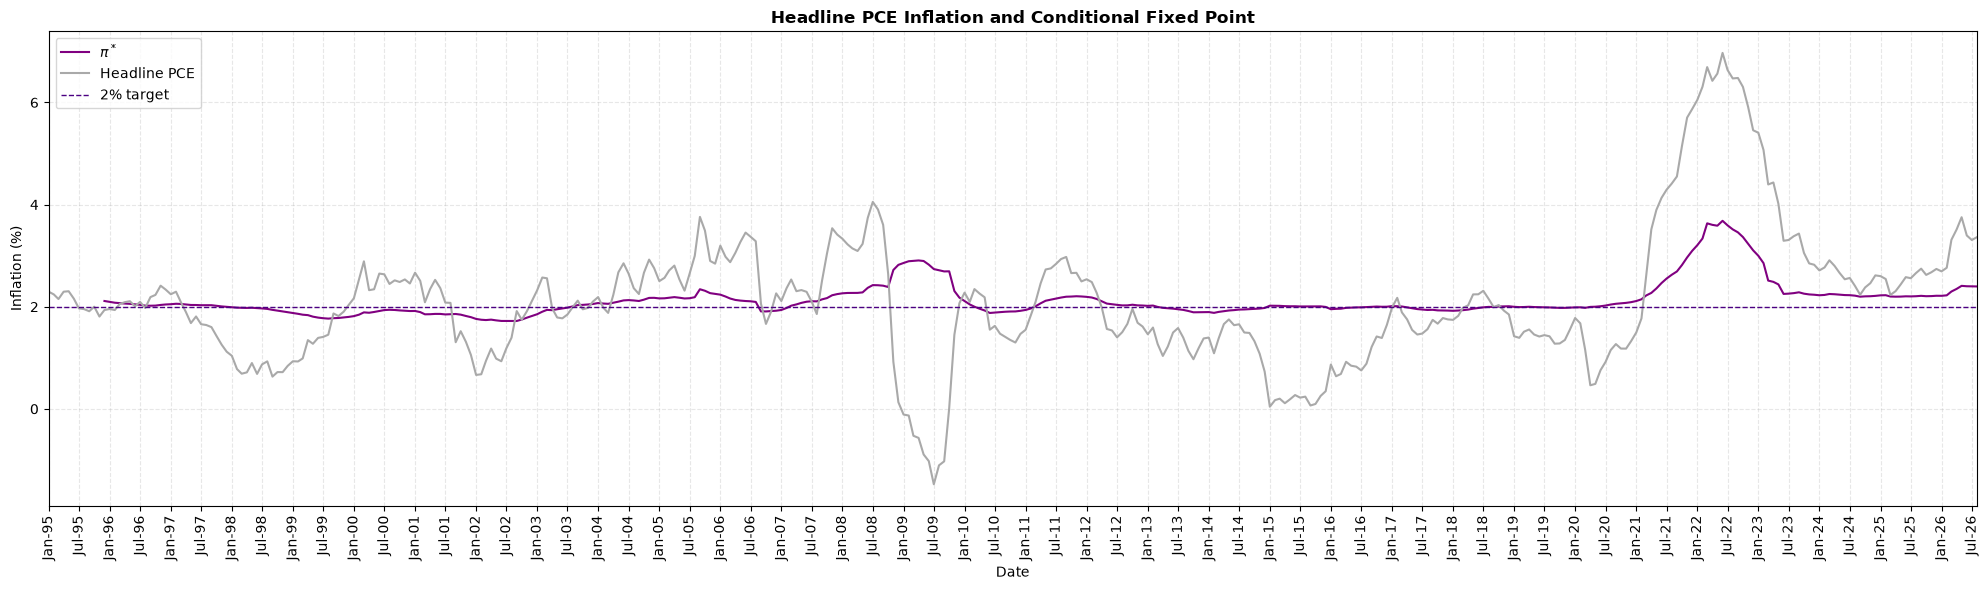

In [45]:
fig, ax = plt.subplots(figsize=(20, 6))

# Conditional fixed point
ax.plot(
    dfFilterResults.index,
    dfFilterResults["piStar"],
    linewidth=1.5,
    color="purple",
    label=r"$\pi^*$"
)

# Headline PCE
ax.plot(
    dfFilterResults.index,
    dfFilterResults["headlinePce"] * 100,
    linewidth=1.5,
    color="darkgrey",
    label="Headline PCE"
)

# 2% target
ax.axhline(
    y=2,
    linewidth=1,
    color="indigo",
    linestyle="--",
    label="2% target"
)

# Y-axis
ax.set_ylabel("Inflation (%)")

# X-axis
ax.set_xlim(
    pd.Timestamp("1995-01-01"),
    dfFilterResults.index.max()
)

ax.xaxis.set_major_locator(
    mdates.MonthLocator(bymonth=[1, 7], bymonthday=1)
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b-%y")
)

ax.tick_params(axis="x", rotation=90)

# Labels and title
ax.set_xlabel("Date")
ax.set_title(
    "Headline PCE Inflation and Conditional Fixed Point",
    fontweight="bold"
)

# Grid
ax.grid(
    True,
    which="major",
    axis="both",
    linestyle="--",
    alpha=0.3
)
ax.set_axisbelow(True)

# Fed hawkish regimes
addHawkishRegimes(
    ax,
    starts,
    ends,
    color="purple",
    alpha=0.05
)

# Legend
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()


# Split-window descriptive statistics

In [46]:
# def descriptive_stats(
#     df,
#     start,
#     end,
#     inflation_col="monthlyPce"
# ):
#     """
#     Descriptive statistics for a given period
#     Skewness: adjusted Fisher-Pearson coefficient (pandas)
#     Kurtosis: excess kurtosis (normal distribution = 0)
#     ACF(1): computed only for monthly PCE inflation
#     """

#     sample = df.loc[start:end]

#     stats = pd.DataFrame(index=df.columns)

#     stats["N"] = sample.count()
#     stats["Mean"] = sample.mean()
#     stats["Median"] = sample.median()
#     stats["Std"] = sample.std()
#     stats["Skewness"] = sample.skew()
#     stats["Kurtosis"] = sample.kurt()
#     stats["Min"] = sample.min()
#     stats["Max"] = sample.max()

#     # Lag-1 autocorrelation of monthly PCE inflation
#     stats["ACF(1)"] = sample[inflation_col].autocorr(lag=1)

#     return stats

def descriptive_stats(data):
    """
    Descriptive statistics for each variable.
    Kurtosis is excess kurtosis (normal distribution = 0).
    """

    stats = pd.DataFrame({
        "Mean": data.mean(),
        "Median": data.median(),
        "Std": data.std(),
        "Min": data.min(),
        "Max": data.max(),
        "Skewness": data.skew(),
        "Kurtosis": data.kurt(),
        "N": data.count()
    })

    return stats

In [47]:
dfTable = pd.DataFrame(index=dfFilterResults.index.copy())

# Inflation
dfTable["monthlyPce"] = dfFilterResults["monthlyPce"] * 100
dfTable["healdinePce"] = dfFilterResults["headlinePce"] * 100

# ISMI and components
dfTable["ISMI"] = dfIsmi["ISMIndex"]*100
dfTable["ISMI+"] = dfIsmi["ISMI+"]*100
dfTable["ISMI-"] = dfIsmi["ISMI-"]*100

# Persistence
dfTable["Rho"] = dfFilterResults["Rho"]

# Conditional fixed point (already expressed in %)
dfTable["PiStar"] = dfFilterResults["piStar"]

dfTable.index = pd.to_datetime(dfTable.index)
dfTable = dfTable.sort_index()

In [48]:
# Periods
periods = {
    "2004-01-2007-09": ("2004-01-01", "2007-09-30"),
    "2023-01-2026-09": ("2023-01-01", "2026-09-30")
}

tables = []

for period, (start, end) in periods.items():

    sample = dfTable.loc[start:end]

    stats = descriptive_stats(sample)

    # # Lag-1 autocorrelation of headline PCE
    # stats["ACF(1)"] = np.nan

    # stats.loc["monthlyPce", "ACF(1)"] = (
    #     sample["monthlyPce"].autocorr(lag=1)
    # )

    # Identify period
    stats.insert(0, "Period", period)

    tables.append(stats)

# Final table
summary = pd.concat(tables)

summary.index.name = "Indicator"

summary = summary.reset_index().set_index(
    ["Period", "Indicator"]
)

summary = summary.iloc[:,:-1].round(4)

print(summary.to_latex(
    float_format="%.1f",
    multicolumn=True,
    multirow=True))

\begin{tabular}{llrrrrrrr}
\toprule
 &  & Mean & Median & Std & Min & Max & Skewness & Kurtosis \\
Period & Indicator &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{7}{*}{2004-01-2007-09} & monthlyPce & 0.2 & 0.2 & 0.2 & -0.3 & 1.0 & 0.3 & 3.1 \\
 & healdinePce & 2.6 & 2.6 & 0.5 & 1.7 & 3.8 & 0.3 & -0.4 \\
 & ISMI & 4.5 & 3.8 & 13.1 & -21.6 & 38.8 & 0.4 & 0.6 \\
 & ISMI+ & 18.1 & 16.9 & 9.4 & 4.8 & 44.8 & 1.1 & 1.2 \\
 & ISMI- & 13.6 & 12.1 & 7.7 & 3.0 & 38.6 & 1.1 & 1.5 \\
 & Rho & 0.5 & 0.5 & 0.1 & 0.3 & 0.7 & 1.4 & 7.2 \\
 & PiStar & 2.1 & 2.1 & 0.1 & 1.9 & 2.3 & -0.3 & 0.5 \\
\cline{1-9}
\multirow[t]{7}{*}{2023-01-2026-09} & monthlyPce & 0.2 & 0.3 & 0.1 & -0.1 & 0.6 & 0.2 & 1.0 \\
 & healdinePce & 3.0 & 2.8 & 0.7 & 2.2 & 5.4 & 1.7 & 2.8 \\
 & ISMI & 1.8 & 1.0 & 7.4 & -16.7 & 29.4 & 0.9 & 4.0 \\
 & ISMI+ & 9.8 & 8.5 & 5.4 & 3.6 & 34.4 & 2.4 & 9.0 \\
 & ISMI- & 8.0 & 7.1 & 4.5 & 1.5 & 25.0 & 1.6 & 4.2 \\
 & Rho & 0.5 & 0.5 & 0.0 & 0.5 & 0.6 & 2.2 & 5.2 \\
 & PiStar & 2.3 & 2.2 & 0.2 &

In [49]:
summary

Mean   Median      Std      Min      Max  \
Period          Indicator                                                  
2004-01-2007-09 monthlyPce    0.2269   0.2463   0.2077  -0.2623   0.9604   
                healdinePce   2.6048   2.5655   0.4843   1.6631   3.7585   
                ISMI          4.5394   3.7596  13.1427 -21.6462  38.7695   
                ISMI+        18.1208  16.8863   9.4342   4.8038  44.8267   
                ISMI-        13.5815  12.1140   7.7367   3.0496  38.5888   
                Rho           0.4629   0.4635   0.0586   0.3378   0.7159   
                PiStar        2.1155   2.1223   0.0992   1.9074   2.3418   
2023-01-2026-09 monthlyPce    0.2404   0.2523   0.1324  -0.1029   0.6261   
                healdinePce   3.0288   2.7538   0.7184   2.2302   5.4068   
                ISMI          1.7996   1.0020   7.4177 -16.6992  29.3688   
                ISMI+         9.8375   8.4545   5.4239   3.5995  34.4470   
                ISMI-         8.0379   7.1045   4.4712   1.4669  24.9561   
                Rho           0.4995   0.4904   0.0360   0.4676   0.6289   
                PiStar        2.2936   2.2290   0.1628   2.1962   2.9974   

                             Skewness  Kurtosis  
Period          Indicator                        
2004-01-2007-09 monthlyPce     0.3123    3.1246  
                healdinePce    0.3006   -0.3850  
                ISMI           0.3600    0.6067  
                ISMI+          1.0769    1.1827  
                ISMI-          1.1330    1.4639  
                Rho            1.3545    7.2191  
                PiStar        -0.3493    0.4713  
2023-01-2026-09 monthlyPce     0.2489    1.0253  
                healdinePce    1.6818    2.8124  
                ISMI           0.8504    4.0138  
                ISMI+          2.4342    8.9830  
                ISMI-          1.5731    4.1601  
                Rho            2.2206    5.1545  
                PiStar         3.0224   10.0741

In [50]:
# # Plot Yoy and Mom series, ISM, S+, S-, Rho...
# xAxis = df.index
# fig, axes = plt.subplots(
#     7, 1,
#     figsize=(20, 20),
#     sharex=True # Align panel together
# )

# ax1, ax2, ax3, ax4, ax5, ax6, ax7 = axes

# ax1.plot(xAxis, df.YoY, color='royalblue')
# ax1.set_title('YoY Headline Inflation')
# ax1.set_ylabel('%')
# ax1.grid()

# ax2.plot(xAxis, df.MoM, color='black')
# ax2.set_title('MoM Headline Inflation')
# ax2.set_ylabel('%')
# ax2.grid()

# ax3.plot(xAxis, df["ISMIndex"], color='darkgreen')
# ax3.set_title('ISM Index')
# ax3.set_ylabel('Index')
# ax3.grid()

# ax4.plot(xAxis, df["ISMI+"], color='orange')
# ax4.set_title('Positive momentum (%)')
# ax4.set_ylabel('%')
# ax4.grid()

# ax5.plot(xAxis, df["ISMI-"], color='red')
# ax5.set_title('Negative momentum (%)')
# ax5.set_ylabel('%')
# ax5.grid()

# ax6.plot(xAxis, df["Rho"], color='black')
# ax6.set_title(r'YoY inflation persistance ($\hat \rho_t$)')
# ax6.set_ylabel('Coefficient')
# ax6.grid()

# ax7.plot(xAxis, df["5y5yExpectations"], color='blue')
# ax7.set_title("5-year inflation expectations in 5 years")
# ax7.set_ylabel('%')
# ax7.grid()

# # Fed Hawkish
# for ax in axes:
#     addHawkishRegimes(
#         ax,
#         starts,
#         ends,
#         color="pink",
#         alpha=0.15
#     )

# # # Add fomc dates (Hike, pink)
# # for ax in axes:
# #     addLinesFomc(ax, fomcDatesRes.Hike, "pink")
    
# # # Add fomc dates (Cut, green)
# # for ax in axes:
# #     addLinesFomc(ax, fomcDatesRes.Cut, "grey")

# plt.tight_layout()
# plt.show()